<a href="https://colab.research.google.com/github/HittersLab/Case-Exercises-Subsea-Integrity-Predictive-Analytics/blob/main/Case2_Corrosion_RUL/Case2_Corrosion_RUL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Case Exercise 2: Corrosion Rate Prediction and Remaining Life

## Question 1: Implement the de Waard Milliams Corrosion Rate Model

### Objective
Implement a reusable Python function to estimate CO2 corrosion rates using the original de Waard Milliams empirical correlation and validate it with unit tests.

### Engineering Principle
The model estimates the corrosion rate of carbon steel exposed to a CO2 containing aqueous environment. The original correlation uses temperature and CO2 partial pressure.

\[
\log_{10}(CR)=7.96-\frac{2320}{T+273.15}
-0.00555T+0.67\log_{10}(p_{CO_2})
\]

Where:
- CR is the estimated corrosion rate in mm/year.
- T is temperature in degrees Celsius.
- p_CO2 is CO2 partial pressure in bar.

The predicted corrosion rate is obtained by calculating the base 10 antilogarithm.

### Assumptions and Limitations
This is an educational implementation of the original empirical correlation. It does not explicitly model pH, protective corrosion-product scales, corrosion inhibitors, water chemistry, flow effects, or localised corrosion.

CO2 partial pressure must be positive and expressed in bar. Total operating pressure must not be substituted directly unless CO2 partial pressure has been determined.

The prediction is a model estimate, not a measured field corrosion rate or an approved engineering design value.


**Imports and Configuration of Python Libraries**

In [1]:

import math
import unittest


def de_waard_milliams_corrosion_rate(
    temperature_c: float,
    co2_partial_pressure_bar: float
) -> float:
    """Estimate CO2 corrosion rate in mm/year using an educational
    implementation of the original de Waard-Milliams correlation."""

    if not isinstance(temperature_c, (int, float)):
        raise TypeError("Temperature must be numeric.")

    if not isinstance(co2_partial_pressure_bar, (int, float)):
        raise TypeError("CO2 partial pressure must be numeric.")

    if not math.isfinite(temperature_c):
        raise ValueError("Temperature must be finite.")

    if not math.isfinite(co2_partial_pressure_bar):
        raise ValueError("CO2 partial pressure must be finite.")

    if co2_partial_pressure_bar <= 0:
        raise ValueError("CO2 partial pressure must be positive.")

    temperature_k = temperature_c + 273.15

    log_rate = (
        7.96
        - 2320 / temperature_k
        - 0.00555 * temperature_c
        + 0.67 * math.log10(co2_partial_pressure_bar)
    )

    return 10 ** log_rate


class TestCorrosionModel(unittest.TestCase):

    def test_hand_calculation(self):
        t, p = 65.0, 2.0
        expected = 10 ** (
            7.96 - 2320 / (t + 273.15)
            - 0.00555 * t + 0.67 * math.log10(p)
        )
        self.assertAlmostEqual(
            de_waard_milliams_corrosion_rate(t, p), expected
        )

    def test_zero_pressure(self):
        with self.assertRaises(ValueError):
            de_waard_milliams_corrosion_rate(65, 0)

    def test_negative_pressure(self):
        with self.assertRaises(ValueError):
            de_waard_milliams_corrosion_rate(65, -1)

    def test_invalid_temperature(self):
        with self.assertRaises(TypeError):
            de_waard_milliams_corrosion_rate("65", 2)

    def test_nan_input(self):
        with self.assertRaises(ValueError):
            de_waard_milliams_corrosion_rate(float("nan"), 2)

    def test_pressure_effect(self):
        low = de_waard_milliams_corrosion_rate(65, 1)
        high = de_waard_milliams_corrosion_rate(65, 2)
        self.assertGreater(high, low)


unittest.main(argv=[""], exit=False)


......
----------------------------------------------------------------------
Ran 6 tests in 0.007s

OK



## Question 2: Generate a Synthetic 10 Years SCADA Dataset

### Objective
Generate ten years of hourly operating observations representing an illustrative subsea production system based on the Usan training case.

### Method
The dataset includes timestamps, asset identifiers, pressure, temperature, water cut, gas CO2 fraction, and CO2 partial pressure. Seasonal variation, random measurement variation, and occasional operating changes are included to make the data more useful for analysis.

### Data Integrity
All generated observations are synthetic and must not be represented as actual Usan field measurements. Parameter ranges are illustrative training assumptions and must be checked against approved operating limits before engineering use.


This generates 87,648 hourly timestamps for the ten calendar years 2020–2029, including leap years, across six illustrative jumper assets.

In [2]:

import numpy as np
import pandas as pd
from pathlib import Path

RANDOM_SEED = 20261019
rng = np.random.default_rng(RANDOM_SEED)

OUTPUT_DIR = Path("data")
OUTPUT_DIR.mkdir(exist_ok=True)

asset_ids = [f"J-{i:03d}" for i in range(1, 7)]

# Ten complete calendar years, including leap years.
timestamps = pd.date_range(
    start="2020-01-01 00:00:00",
    end="2030-01-01 00:00:00",
    freq="h",
    inclusive="left"
)

frames = []

for asset_id in asset_ids:
    n = len(timestamps)
    hour_index = np.arange(n)

    # Illustrative operating conditions, not field measurements.
    pressure_psi = (
        3900
        + 180 * np.sin(2 * np.pi * hour_index / (24 * 30))
        + rng.normal(0, 100, n)
    )
    pressure_psi = np.clip(pressure_psi, 2500, 4467)

    temperature_c = (
        65
        + 5 * np.sin(2 * np.pi * hour_index / (24 * 365.25))
        + rng.normal(0, 2.5, n)
    )
    temperature_c = np.clip(temperature_c, 35, 85)

    water_cut_pct = np.clip(
        35 + 0.5 * hour_index / 24 / 365.25
        + rng.normal(0, 5, n),
        5, 85
    )

    co2_fraction = rng.uniform(0.01, 0.05, n)

    # Convert total pressure from psi to bar, then estimate CO2
    # partial pressure using the illustrative gas CO2 fraction.
    total_pressure_bar = pressure_psi / 14.5038
    co2_partial_pressure_bar = total_pressure_bar * co2_fraction

    frame = pd.DataFrame({
        "timestamp": timestamps,
        "asset_id": asset_id,
        "pressure_psi": pressure_psi,
        "temperature_c": temperature_c,
        "water_cut_pct": water_cut_pct,
        "co2_fraction": co2_fraction,
        "co2_partial_pressure_bar": co2_partial_pressure_bar
    })

    frames.append(frame)

scada = pd.concat(frames, ignore_index=True)

scada.to_csv(
    OUTPUT_DIR / "synthetic_10_year_scada.csv",
    index=False
)

print("Dataset created:", scada.shape)
print("Assets:", scada["asset_id"].nunique())
print("Start:", scada["timestamp"].min())
print("End:", scada["timestamp"].max())
print(scada.head())


Dataset created: (526032, 7)
Assets: 6
Start: 2020-01-01 00:00:00
End: 2029-12-31 23:00:00
            timestamp asset_id  pressure_psi  temperature_c  water_cut_pct  \
0 2020-01-01 00:00:00    J-001   3906.240435      65.966260      40.721032   
1 2020-01-01 01:00:00    J-001   3793.595673      68.039344      39.001817   
2 2020-01-01 02:00:00    J-001   3944.761319      66.389354      30.279094   
3 2020-01-01 03:00:00    J-001   3970.068457      67.888339      38.159234   
4 2020-01-01 04:00:00    J-001   3859.999303      68.436564      29.160353   

   co2_fraction  co2_partial_pressure_bar  
0      0.027687                  7.456894  
1      0.015251                  3.988988  
2      0.047013                 12.786562  
3      0.030577                  8.369722  
4      0.016613                  4.421338  



## Question 3: Physics Feature Pipeline and Monthly Corrosion Rates

### Objective
Apply a reusable physics feature pipeline to the synthetic SCADA data and calculate monthly average corrosion rates for each jumper.

### Method
The pipeline derives CO2 partial pressure in bar where needed and applies the de Waard–Milliams correlation to estimate corrosion rate. Monthly averages are calculated by asset and calendar month.

### Limitation
The original correlation may produce high estimates outside its applicable calibration range. The resulting values are model predictions for training, not validated field corrosion rates. No machine-learning model is trained in this step.


In [3]:

class PhysicsFeaturePipeline:
    """Create physics-based corrosion features from SCADA observations."""

    def transform(self, data: pd.DataFrame) -> pd.DataFrame:
        required = {
            "timestamp",
            "asset_id",
            "temperature_c",
            "co2_partial_pressure_bar"
        }

        missing = required - set(data.columns)
        if missing:
            raise ValueError(f"Missing required columns: {sorted(missing)}")

        result = data.copy()
        result["timestamp"] = pd.to_datetime(result["timestamp"])

        if (
            result["temperature_c"].isna().any()
            or result["co2_partial_pressure_bar"].isna().any()
        ):
            raise ValueError("Temperature and CO2 pressure cannot be missing.")

        if (
            result["co2_partial_pressure_bar"] <= 0
        ).any():
            raise ValueError("CO2 partial pressure must be positive.")

        temperature = result["temperature_c"].to_numpy()
        co2_pressure = result["co2_partial_pressure_bar"].to_numpy()

        log_rate = (
            7.96
            - 2320 / (temperature + 273.15)
            - 0.00555 * temperature
            + 0.67 * np.log10(co2_pressure)
        )

        result["predicted_corrosion_rate_mm_y"] = 10 ** log_rate
        result["month"] = (
            result["timestamp"].dt.to_period("M").dt.to_timestamp()
        )

        return result


pipeline = PhysicsFeaturePipeline()
enriched_scada = pipeline.transform(scada)

monthly_corrosion = (
    enriched_scada
    .groupby(["asset_id", "month"], as_index=False)
    ["predicted_corrosion_rate_mm_y"]
    .mean()
    .rename(columns={
        "predicted_corrosion_rate_mm_y":
        "monthly_average_corrosion_rate_mm_y"
    })
)

enriched_scada.to_csv(
    OUTPUT_DIR / "enriched_corrosion_scada.csv",
    index=False
)

monthly_corrosion.to_csv(
    OUTPUT_DIR / "monthly_average_corrosion_rates.csv",
    index=False
)

print(monthly_corrosion.head())
print("Monthly records:", len(monthly_corrosion))


  asset_id      month  monthly_average_corrosion_rate_mm_y
0    J-001 2020-01-01                            22.883828
1    J-001 2020-02-01                            24.516255
2    J-001 2020-03-01                            25.852778
3    J-001 2020-04-01                            25.419767
4    J-001 2020-05-01                            24.828753
Monthly records: 720


**Validation checks**

In [4]:

assert enriched_scada["predicted_corrosion_rate_mm_y"].notna().all()
assert (enriched_scada["predicted_corrosion_rate_mm_y"] > 0).all()
assert enriched_scada["asset_id"].nunique() == 6
assert len(monthly_corrosion) == 6 * 120

print("Validation passed.")
print("Six assets × 120 months = 720 monthly averages.")


Validation passed.
Six assets × 120 months = 720 monthly averages.



## Question 4: Remaining Useful Life and Risk Classification

### Objective
Estimate remaining useful life (RUL) for the six jumpers using their current wall thickness and supplied corrosion rates. Visualise RUL against corrosion rate and classify risk.

### Engineering Principle
Under a simplified constant-corrosion-rate assumption:

\[
RUL=\frac{t_{\text{current}}-t_{\text{minimum}}}{CR}
\]

Where:
- Current wall thickness is measured in mm.
- Minimum allowable wall thickness is measured in mm.
- Corrosion rate is measured in mm/year.
- RUL is estimated in years.

### Assumptions
The minimum allowable wall thickness is assumed to be 6 mm solely for this exercise because the case data does not specify it. This value must be replaced by the approved engineering limit before operational use.

The supplied corrosion rates are treated as constant for the calculation. Risk bands are illustrative screening categories, not approved integrity-management criteria.


In [5]:

import matplotlib.pyplot as plt

jumpers = pd.DataFrame({
    "jumper_id": ["J-001", "J-002", "J-003", "J-004", "J-005", "J-006"],
    "original_wall_thickness_mm": [12.7, 12.7, 12.7, 10.3, 12.7, 12.7],
    "current_wall_thickness_mm": [11.2, 10.8, 11.5, 8.9, 10.1, 11.0],
    "corrosion_rate_mm_y": [0.15, 0.19, 0.12, 0.14, 0.26, 0.17],
    "operating_pressure_psi": [4200, 4400, 3800, 3200, 4467, 4100],
    "temperature_c": [65, 72, 58, 55, 78, 68],
    "water_cut_pct": [32, 45, 28, 38, 62, 40]
})

# Educational assumption only: replace with approved engineering value.
MINIMUM_WALL_THICKNESS_MM = 6.0

jumpers["remaining_wall_allowance_mm"] = (
    jumpers["current_wall_thickness_mm"]
    - MINIMUM_WALL_THICKNESS_MM
)

if (jumpers["remaining_wall_allowance_mm"] < 0).any():
    raise ValueError("A jumper is already below the assumed minimum thickness.")

jumpers["estimated_rul_years"] = (
    jumpers["remaining_wall_allowance_mm"]
    / jumpers["corrosion_rate_mm_y"]
)

def classify_risk(rul_years):
    if rul_years < 5:
        return "High"
    elif rul_years < 10:
        return "Medium"
    return "Low"

jumpers["risk_classification"] = (
    jumpers["estimated_rul_years"].apply(classify_risk)
)

jumpers.to_csv(
    OUTPUT_DIR / "jumper_corrosion_rul_enriched.csv",
    index=False
)

print(jumpers[[
    "jumper_id",
    "corrosion_rate_mm_y",
    "remaining_wall_allowance_mm",
    "estimated_rul_years",
    "risk_classification"
]].round(2))


  jumper_id  corrosion_rate_mm_y  remaining_wall_allowance_mm  \
0     J-001                 0.15                          5.2   
1     J-002                 0.19                          4.8   
2     J-003                 0.12                          5.5   
3     J-004                 0.14                          2.9   
4     J-005                 0.26                          4.1   
5     J-006                 0.17                          5.0   

   estimated_rul_years risk_classification  
0                34.67                 Low  
1                25.26                 Low  
2                45.83                 Low  
3                20.71                 Low  
4                15.77                 Low  
5                29.41                 Low  


**RUL visualisation**

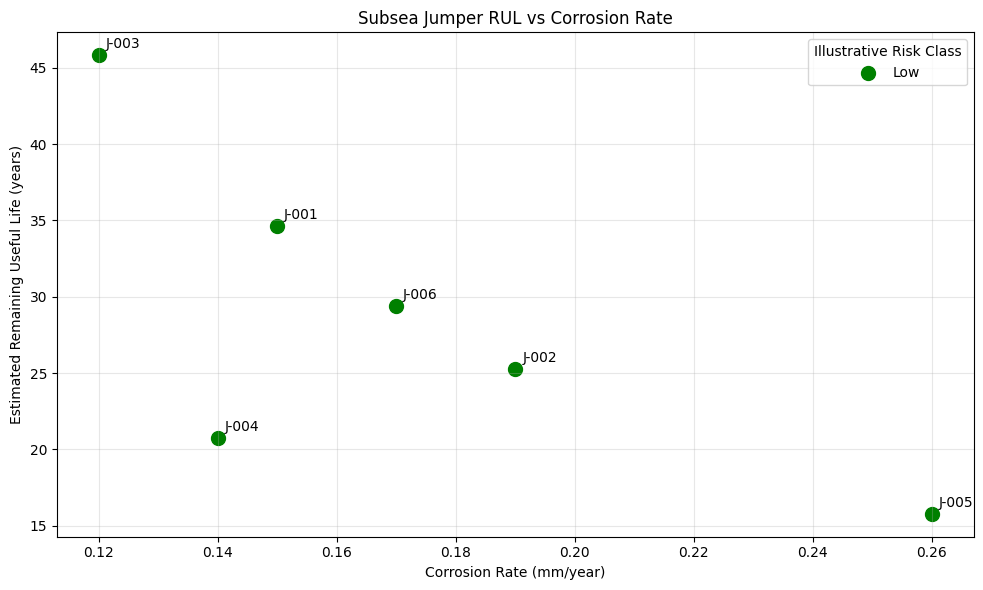

In [6]:

risk_colors = {
    "Low": "green",
    "Medium": "orange",
    "High": "red"
}

plt.figure(figsize=(10, 6))

for risk, group in jumpers.groupby("risk_classification"):
    plt.scatter(
        group["corrosion_rate_mm_y"],
        group["estimated_rul_years"],
        label=risk,
        color=risk_colors[risk],
        s=100
    )

for _, row in jumpers.iterrows():
    plt.annotate(
        row["jumper_id"],
        (row["corrosion_rate_mm_y"], row["estimated_rul_years"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel("Corrosion Rate (mm/year)")
plt.ylabel("Estimated Remaining Useful Life (years)")
plt.title("Subsea Jumper RUL vs Corrosion Rate")
plt.legend(title="Illustrative Risk Class")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Final checks and deliverables**

In [7]:

assert len(jumpers) == 6
assert jumpers["estimated_rul_years"].notna().all()
assert (jumpers["estimated_rul_years"] > 0).all()

print("Case 2 deliverables saved:")
for file_name in [
    "synthetic_10_year_scada.csv",
    "enriched_corrosion_scada.csv",
    "monthly_average_corrosion_rates.csv",
    "jumper_corrosion_rul_enriched.csv"
]:
    print(OUTPUT_DIR / file_name)


Case 2 deliverables saved:
data/synthetic_10_year_scada.csv
data/enriched_corrosion_scada.csv
data/monthly_average_corrosion_rates.csv
data/jumper_corrosion_rul_enriched.csv
